**15.071 The AI Edge** · Project 1: Predictive AI · Fall 2026 · MIT Sloan School of Management

Team: Audrey DeVault, Paul Bustarret, Charles Loriot, Sara Alafifi

---

# Slide figures: the queue's speculative flood

Investor-deck versions of [01_charles_tabular_models](01_charles_tabular_models.ipynb)'s figure 01, split into **two separate charts** for slide 2:

| Figure | Shows |
|---|---|
| `12_queue_entries.png` | Projects entering the queue each year |
| `13_build_rate.png` | Share of those projects built within 5 years |

Same labeled projects as the pipeline (`data.modeling_table`, six operators, entries 2005–2020). Read-only: nothing is fit or scored, and the test cohort's model scores are not touched. Styled to match the deck (Arial, the deck's background and blue, no train/test shading).

## Setup

In [1]:
import logging, os, sys
from pathlib import Path

# The project root is the folder holding pyproject.toml, found by walking up
# from wherever this notebook is opened.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from queue_risk import config, data

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # falls back if Arial is missing
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)

# Deck palette (Queue Risk AI slides)
BG, INK, MUTED, BLUE, BAR, GRID = "#F4F3EE", "#1B2430", "#5A6270", "#2A6FDB", "#C9CDD3", "#DDDBD3"
plt.rcParams.update({"font.family": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 13,
                     "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED})

## The numbers

Entries and the 5-year build rate by entry year. These are the values both charts plot.

In [2]:
projects = data.modeling_table(data.load_raw_queue())   # built within config.HORIZON = 5 years
by_year = projects.groupby("q_year")["built"].agg(projects="size", rate="mean")
years = by_year.index.astype(int).tolist()
n = by_year["projects"].tolist()
rate = (100 * by_year["rate"]).tolist()
LAST = years[-1]

print(f"{len(projects):,} labeled projects, entries {years[0]}–{LAST}")
print(f"Entries: {n[years.index(2014)]:,} in 2014 -> {n[-1]:,} in {LAST} ({n[-1] / n[years.index(2014)]:.1f}x)")
print(f"Built within {config.HORIZON} years: {rate[years.index(2014)]:.0f}% (2014) -> {rate[-1]:.0f}% ({LAST})")
by_year.assign(rate=(100 * by_year["rate"]).round(1)).rename(columns={"rate": "built within 5y (%)"}).T

10,685 labeled projects, entries 2005–2020
Entries: 365 in 2014 -> 1,721 in 2020 (4.7x)
Built within 5 years: 20% (2014) -> 3% (2020)


q_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
projects,211.0,328.0,426.0,557.0,384.0,716.0,589.0,193.0,251.0,365.0,550.0,903.0,960.0,1071.0,1460.0,1721.0
built within 5y (%),23.2,15.5,6.6,6.1,8.9,7.4,6.5,21.2,19.1,20.0,14.5,10.3,7.7,5.7,4.6,3.0


In [3]:
def deck_axes(title):
    """One chart in the deck's style: no y-axis, left-aligned title, four year ticks."""
    fig, ax = plt.subplots(figsize=(6.4, 3.8), facecolor=BG)
    ax.set_facecolor(BG)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(length=0)
    ax.set_xticks([2005, 2010, 2015, 2020])
    ax.set_yticks([])
    ax.set_title(title, loc="left", fontsize=15, color=INK, pad=14)
    return fig, ax


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200, facecolor=BG)
    print("saved reports/figures/" + name)
    plt.show()

## Chart 1: projects entering the queue each year

saved reports/figures/12_queue_entries.png


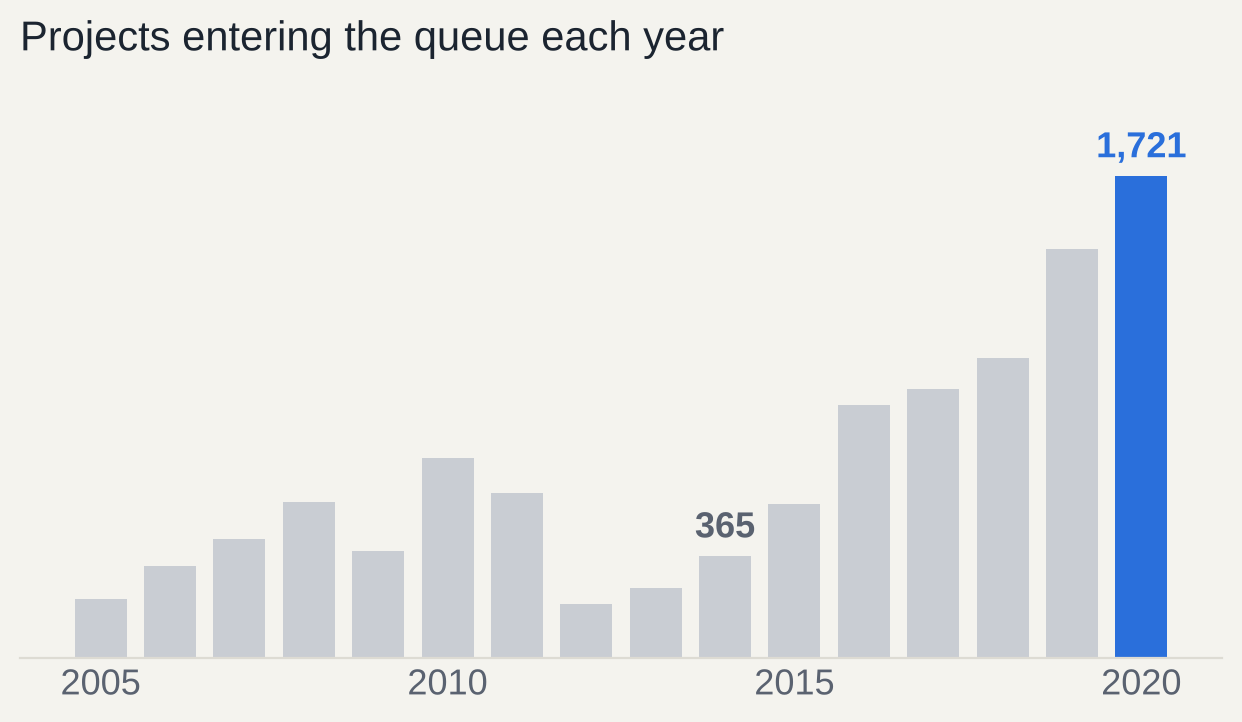

In [4]:
fig, ax = deck_axes("Projects entering the queue each year")
ax.bar(years, n, color=[BLUE if y == LAST else BAR for y in years], width=0.75)
for y, v in zip(years, n):
    if y in (2014, LAST):
        ax.text(y, v + 40, f"{v:,}", ha="center", va="bottom", fontsize=13,
                color=BLUE if y == LAST else MUTED, fontweight="bold")
ax.set_ylim(0, max(n) * 1.18)
save(fig, "12_queue_entries.png")

## Chart 2: share built within 5 years

The 2012–2014 bump is real: entries dipped in those years and a larger share of them was built.

saved reports/figures/13_build_rate.png


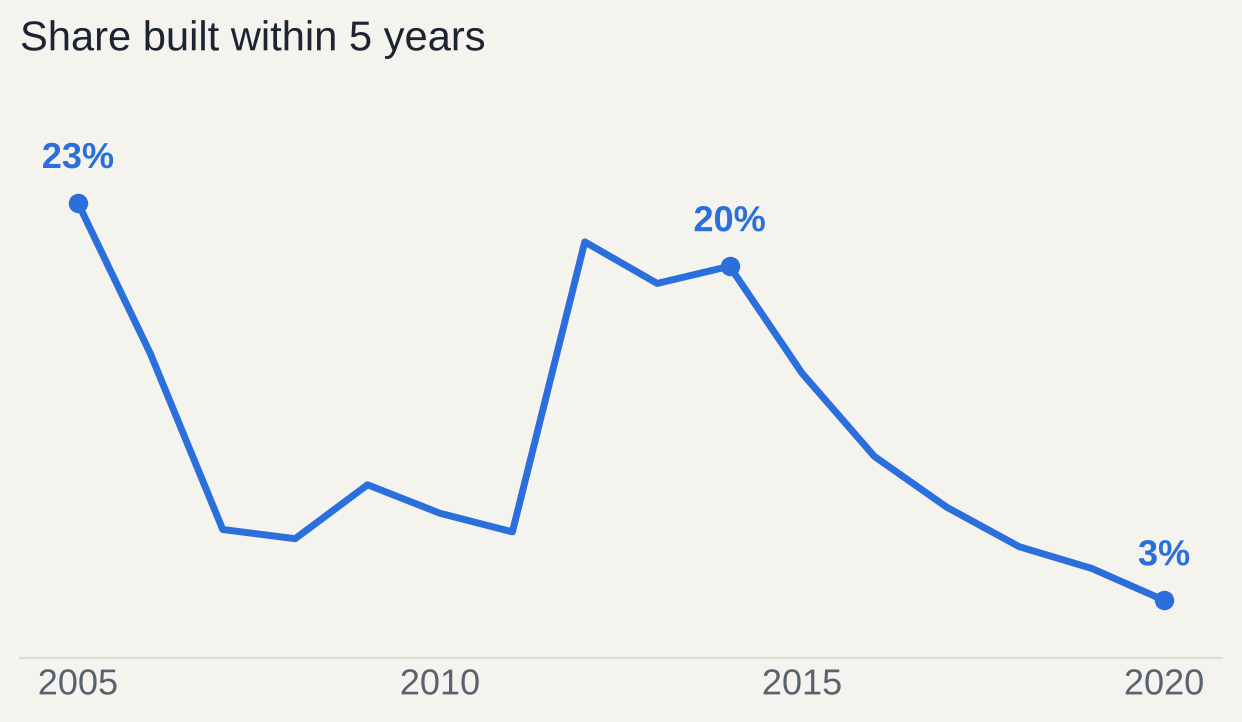

In [5]:
fig, ax = deck_axes(f"Share built within {config.HORIZON} years")
ax.plot(years, rate, color=BLUE, lw=2.5)
marks = (years[0], 2014, LAST)
ax.scatter(marks, [rate[years.index(y)] for y in marks], color=BLUE, zorder=3, s=36)
for y in marks:
    v = rate[years.index(y)]
    ax.text(y, v + 1.4, f"{v:.0f}%", ha="center", va="bottom", fontsize=13, color=BLUE, fontweight="bold")
ax.set_ylim(0, max(rate) * 1.25)
ax.set_xlim(years[0] - 0.8, LAST + 0.8)
save(fig, "13_build_rate.png")

## For the slide

Suggested title: *Queue entries rose almost 5× from 2014 to 2020, while the share built within 5 years fell from 20% to 3%.*

Source line: Berkeley Lab, *Queued Up* (data through end-2025); six grid operators (CAISO, ERCOT, MISO, NYISO, PJM, SPP), clean-energy projects entering 2005–2020.